# Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import glob
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = [15, 8]

# Load data

In [2]:
DATA_DIR = '../../data/other_data/'

In [3]:
filename = DATA_DIR + "friedman.csv"
df = pd.read_csv(filename, index_col='time', header=0, parse_dates=True, date_format='%Y-%m-%d %H:%M:%S')
df

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,y
time,,,,,,,,,,,
2000-01-01 00:00:00,0.773956,0.438878,0.858598,0.697368,0.094177,0.975622,0.761140,0.786064,0.128114,0.450386,19.027630
2000-01-01 01:00:00,0.733640,0.487667,0.837125,0.709907,0.129101,0.900784,0.740484,0.713840,0.198065,0.468514,17.572464
2000-01-01 02:00:00,0.736085,0.474353,0.850482,0.728229,0.194029,0.830169,0.713108,0.646836,0.193688,0.489967,18.751122
2000-01-01 03:00:00,0.736953,0.523669,0.798016,0.692452,0.221582,0.766100,0.654789,0.629723,0.197010,0.507952,19.548968
2000-01-01 04:00:00,0.706973,0.554570,0.788241,0.654443,0.282650,0.769966,0.628058,0.595583,0.245559,0.471132,17.477635
...,...,...,...,...,...,...,...,...,...,...,...
2005-09-14 03:00:00,0.462964,0.598447,0.459439,0.529004,0.477175,0.452375,0.518448,0.445432,0.366518,0.533774,16.335852
2005-09-14 04:00:00,0.441740,0.579851,0.419230,0.537931,0.429486,0.471126,0.544497,0.405278,0.376691,0.561740,15.052065
2005-09-14 05:00:00,0.448282,0.565324,0.418598,0.562605,0.451808,0.522087,0.544653,0.381407,0.386947,0.568343,14.790545


In [4]:
df.describe()

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,y
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.499487,0.501027,0.498697,0.501277,0.499707,0.497740,0.498975,0.501308,0.499675,0.496676,14.597547
std,0.066867,0.065415,0.066401,0.066451,0.065692,0.065664,0.065524,0.067042,0.067228,0.065680,1.610762
min,0.256025,0.222481,0.253552,0.245281,0.094177,0.223320,0.260557,0.210611,0.128114,0.239424,8.177483
25%,0.453585,0.456692,0.453218,0.456190,0.454968,0.452554,0.454312,0.455498,0.454015,0.452297,13.501578
50%,0.499508,0.500797,0.498401,0.501759,0.500356,0.497932,0.499099,0.501937,0.499973,0.496816,14.602549
75%,0.545358,0.545975,0.543179,0.546472,0.545315,0.542305,0.543122,0.547441,0.545958,0.541077,15.688082
max,0.773956,0.741981,0.858598,0.758978,0.776233,0.975622,0.766145,0.786064,0.757188,0.757244,21.233898


In [5]:
df.dtypes

x1     float64
x2     float64
x3     float64
x4     float64
x5     float64
x6     float64
x7     float64
x8     float64
x9     float64
x10    float64
y      float64
dtype: object

# Data preprocessing

## Missing values (without filled seconds)

In [6]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
x1,50000,0,0.0
x2,50000,0,0.0
x3,50000,0,0.0
x4,50000,0,0.0
x5,50000,0,0.0
x6,50000,0,0.0
x7,50000,0,0.0
x8,50000,0,0.0
x9,50000,0,0.0
x10,50000,0,0.0


## Time-index

Sort

In [7]:
df = df.sort_index()
df.index

DatetimeIndex(['2000-01-01 00:00:00', '2000-01-01 01:00:00',
               '2000-01-01 02:00:00', '2000-01-01 03:00:00',
               '2000-01-01 04:00:00', '2000-01-01 05:00:00',
               '2000-01-01 06:00:00', '2000-01-01 07:00:00',
               '2000-01-01 08:00:00', '2000-01-01 09:00:00',
               ...
               '2005-09-13 22:00:00', '2005-09-13 23:00:00',
               '2005-09-14 00:00:00', '2005-09-14 01:00:00',
               '2005-09-14 02:00:00', '2005-09-14 03:00:00',
               '2005-09-14 04:00:00', '2005-09-14 05:00:00',
               '2005-09-14 06:00:00', '2005-09-14 07:00:00'],
              dtype='datetime64[ns]', name='time', length=50000, freq=None)

Check duplicated timestamps

In [8]:
df.index.duplicated().sum()

np.int64(0)

No duplicates

## Time range

In [9]:
print('We have data from:', df.index.min(),
      '\nuntil:', df.index.max())

We have data from: 2000-01-01 00:00:00 
until: 2005-09-14 07:00:00


## Time frequency
Perfect 1-hour frequency

In [10]:
print("Mean:", df.index.diff().mean(), 
      "\nStd:", df.index.diff().std(), 
      "\nMin:", df.index.diff().min(), 
      "\nMax:", df.index.diff().max())

Mean: 0 days 01:00:00 
Std: 0 days 00:00:00 
Min: 0 days 01:00:00 
Max: 0 days 01:00:00


In [11]:
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df.index).min(),
        pd.DatetimeIndex(df.index).max(), 
        freq='h'
    )
)
df = full_range.join(df, how='left').squeeze()

## Missing values with all minutes filled

In [12]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
x1,50000,0,0.0
x2,50000,0,0.0
x3,50000,0,0.0
x4,50000,0,0.0
x5,50000,0,0.0
x6,50000,0,0.0
x7,50000,0,0.0
x8,50000,0,0.0
x9,50000,0,0.0
x10,50000,0,0.0


Nothing has changed (no missing timestamps)

# Data Analysis

## Correlation matrix

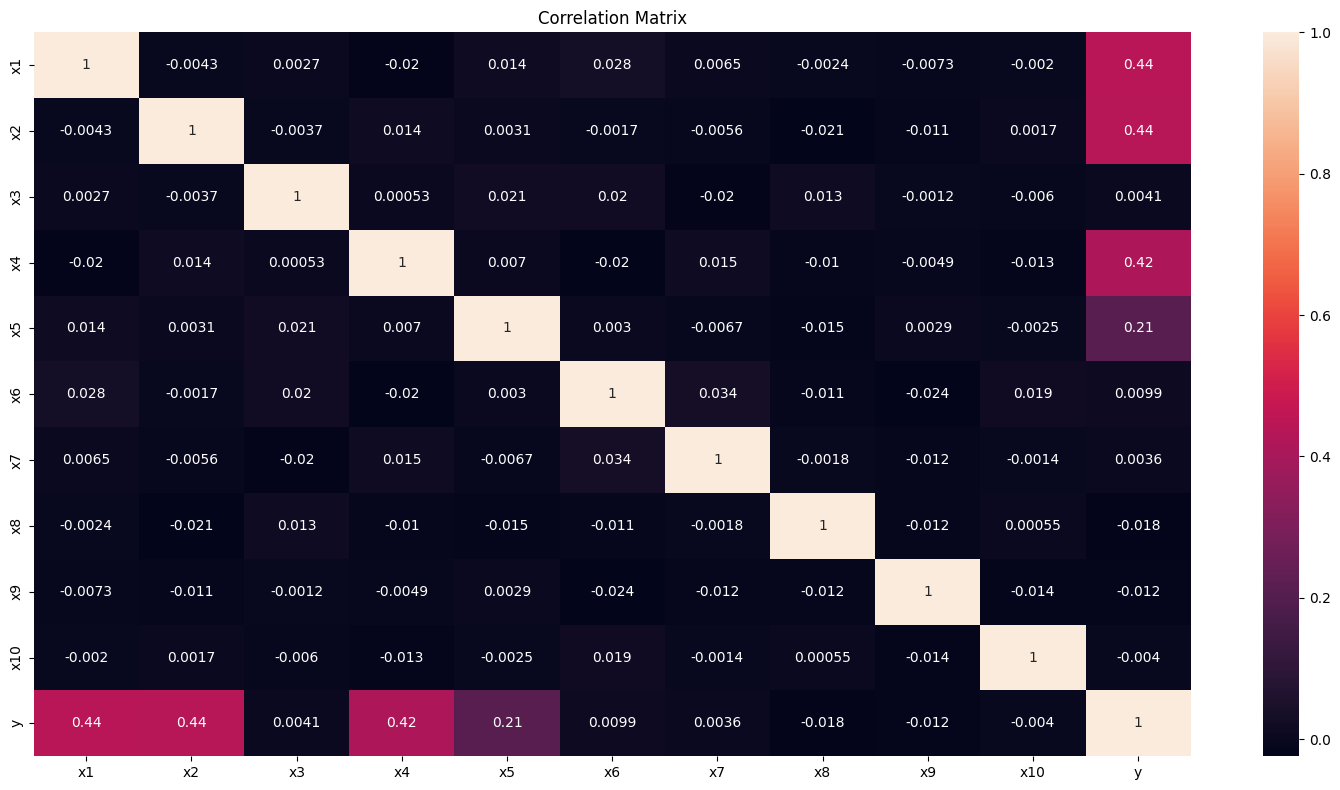

In [13]:
# Fill missing values with the median of each column before calculating correlation
sns.heatmap(df.fillna(df.median(numeric_only=True)).corr(), annot=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## Feature Analysis

Text(0.5, 1.0, 'Y')

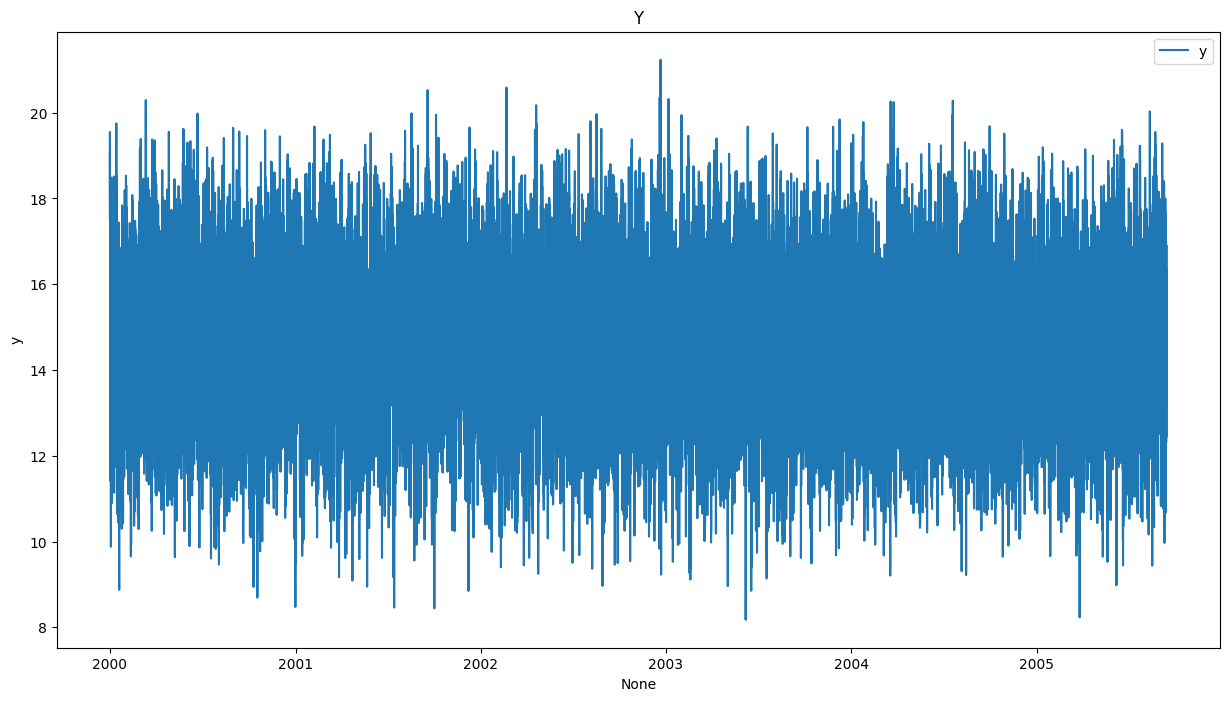

In [24]:
sns.lineplot(data=df, x=df.index, y='y', label='y')
plt.title('Y')

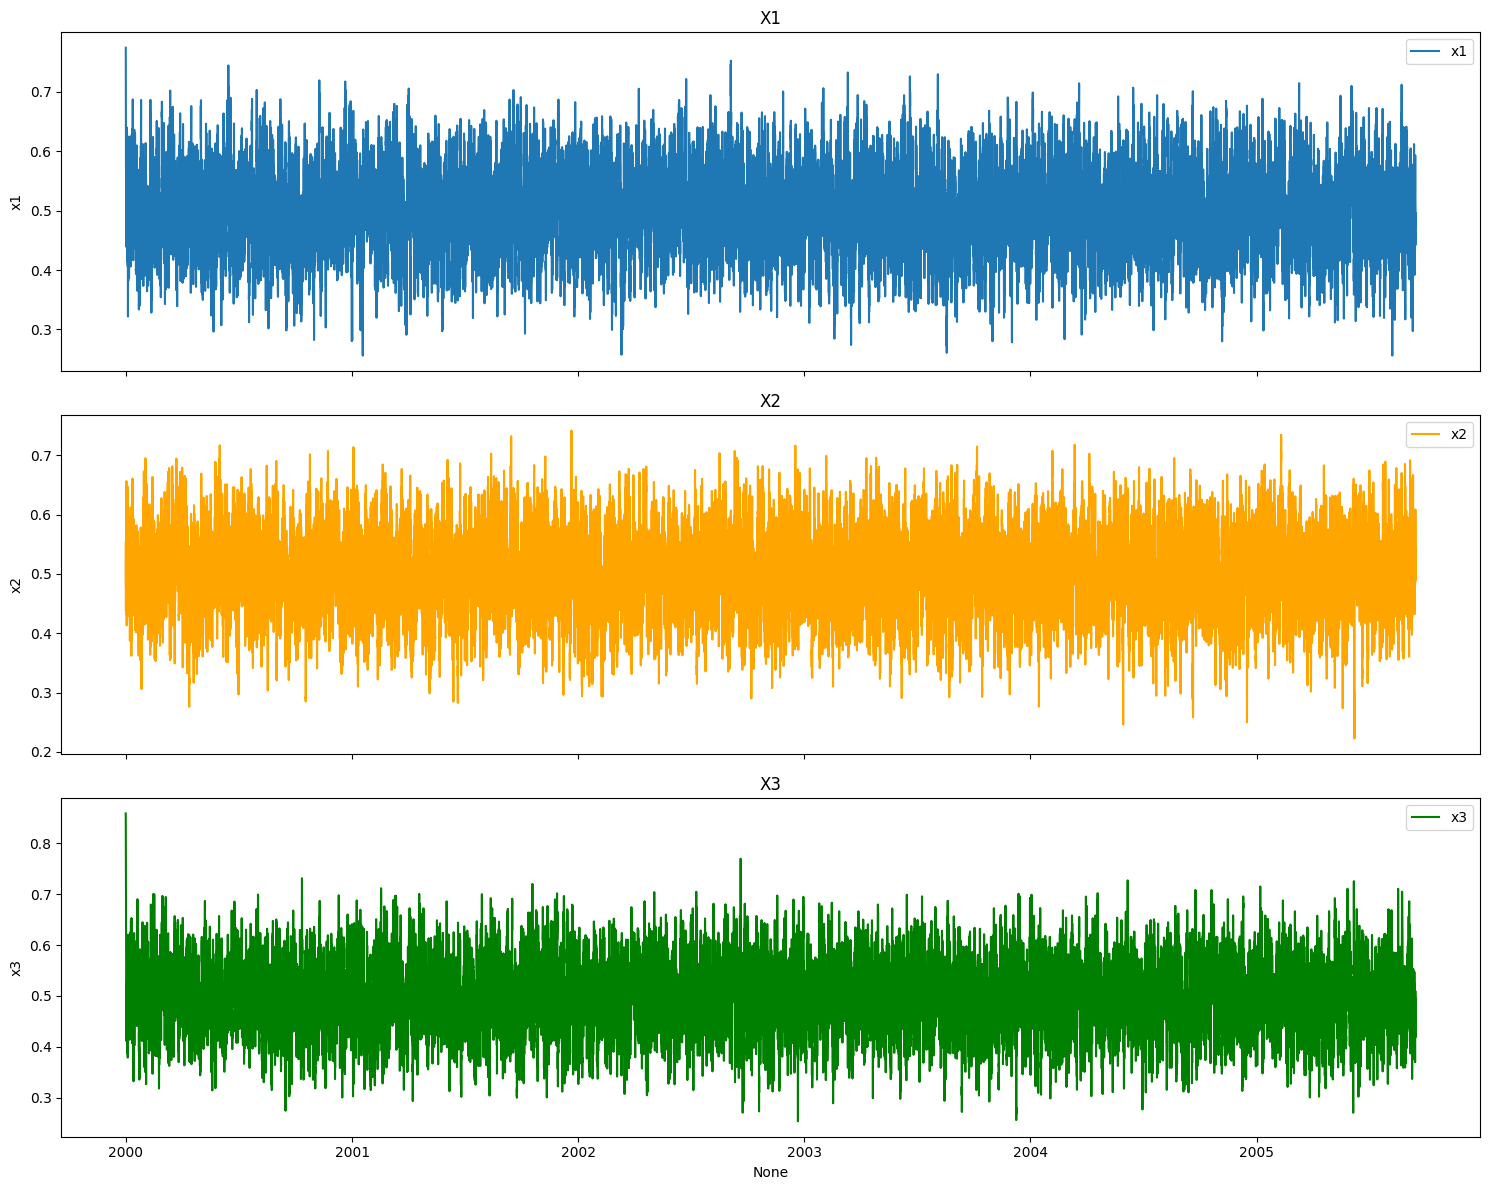

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
sns.lineplot(data=df, x=df.index, y='x1', ax=axes[0], label='x1')
axes[0].set_title('X1')
sns.lineplot(data=df, x=df.index, y='x2', ax=axes[1], label='x2', color='orange')
axes[1].set_title('X2')
sns.lineplot(data=df, x=df.index, y='x3', ax=axes[2], label='x3', color='green')
axes[2].set_title('X3')
plt.tight_layout()
plt.show()

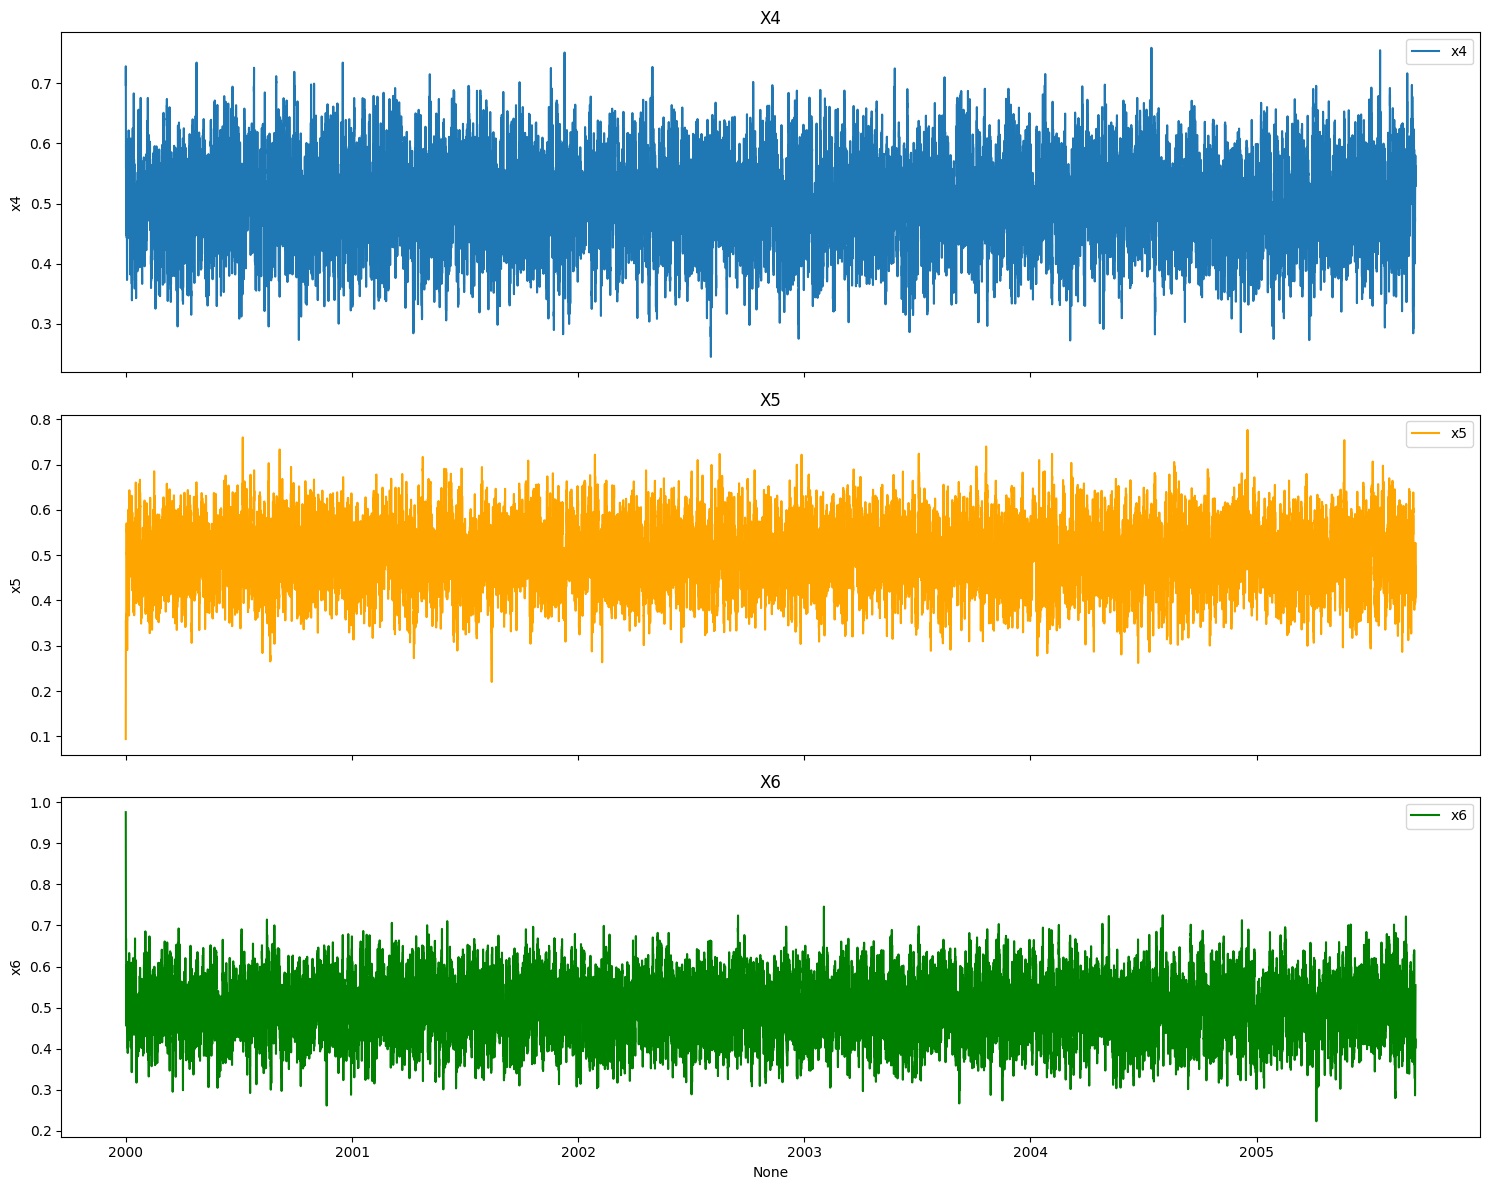

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
sns.lineplot(data=df, x=df.index, y='x4', ax=axes[0], label='x4')
axes[0].set_title('X4')
sns.lineplot(data=df, x=df.index, y='x5', ax=axes[1], label='x5', color='orange')
axes[1].set_title('X5')
sns.lineplot(data=df, x=df.index, y='x6', ax=axes[2], label='x6', color='green')
axes[2].set_title('X6')
plt.tight_layout()
plt.show()

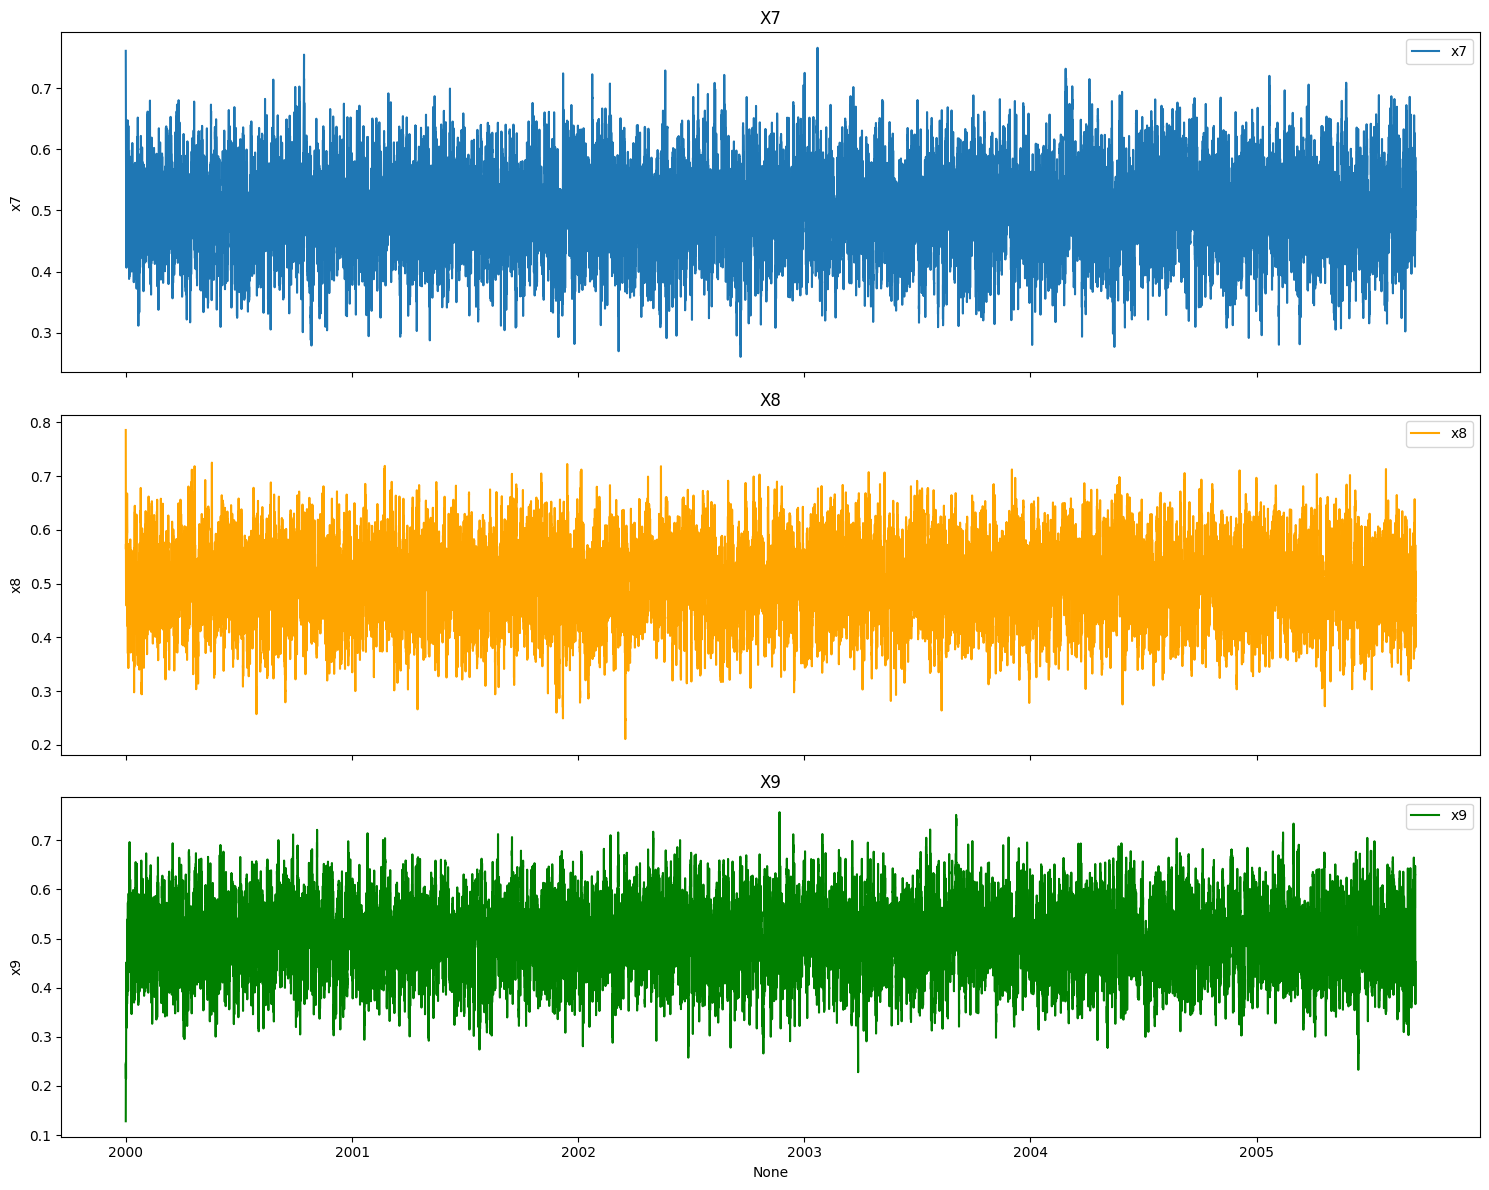

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
sns.lineplot(data=df, x=df.index, y='x7', ax=axes[0], label='x7')
axes[0].set_title('X7')
sns.lineplot(data=df, x=df.index, y='x8', ax=axes[1], label='x8', color='orange')
axes[1].set_title('X8')
sns.lineplot(data=df, x=df.index, y='x9', ax=axes[2], label='x9', color='green')
axes[2].set_title('X9')
plt.tight_layout()
plt.show()

## Peaks detection

In [19]:
from scipy.signal import find_peaks

def normalize_zscore(y):
    return (y - np.mean(y)) / np.std(y)

def robust_zscore(y):
    y = np.array(y)
    med = np.median(y)
    mad = np.median(np.abs(y - med))
    return (y - med) / (mad if mad > 1e-6 else 1)

def plot_spikes_and_drops(x, y, title="Signal with Spikes and Drops", prominence=1.0, robust=False):

    if robust:
        y_pred_norm = robust_zscore(y)
    else:
        y_pred_norm = normalize_zscore(y)
    peaks, _ = find_peaks(y_pred_norm, prominence=prominence)  # use normalized threshold
    drops, _ = find_peaks(-y_pred_norm, prominence=prominence)  # use normalized threshold

    plt.figure(figsize=(15, 9))
    plt.plot(x, y, label="Signal", color="gray")
    plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
    plt.plot(x[drops], y[drops], "bv", label="Drops")
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_11964\555613157.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
C:\Users\HP\AppData\Local\Temp\ipykernel_11964\555613157.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[drops], y[drops], "bv", label="Drops")


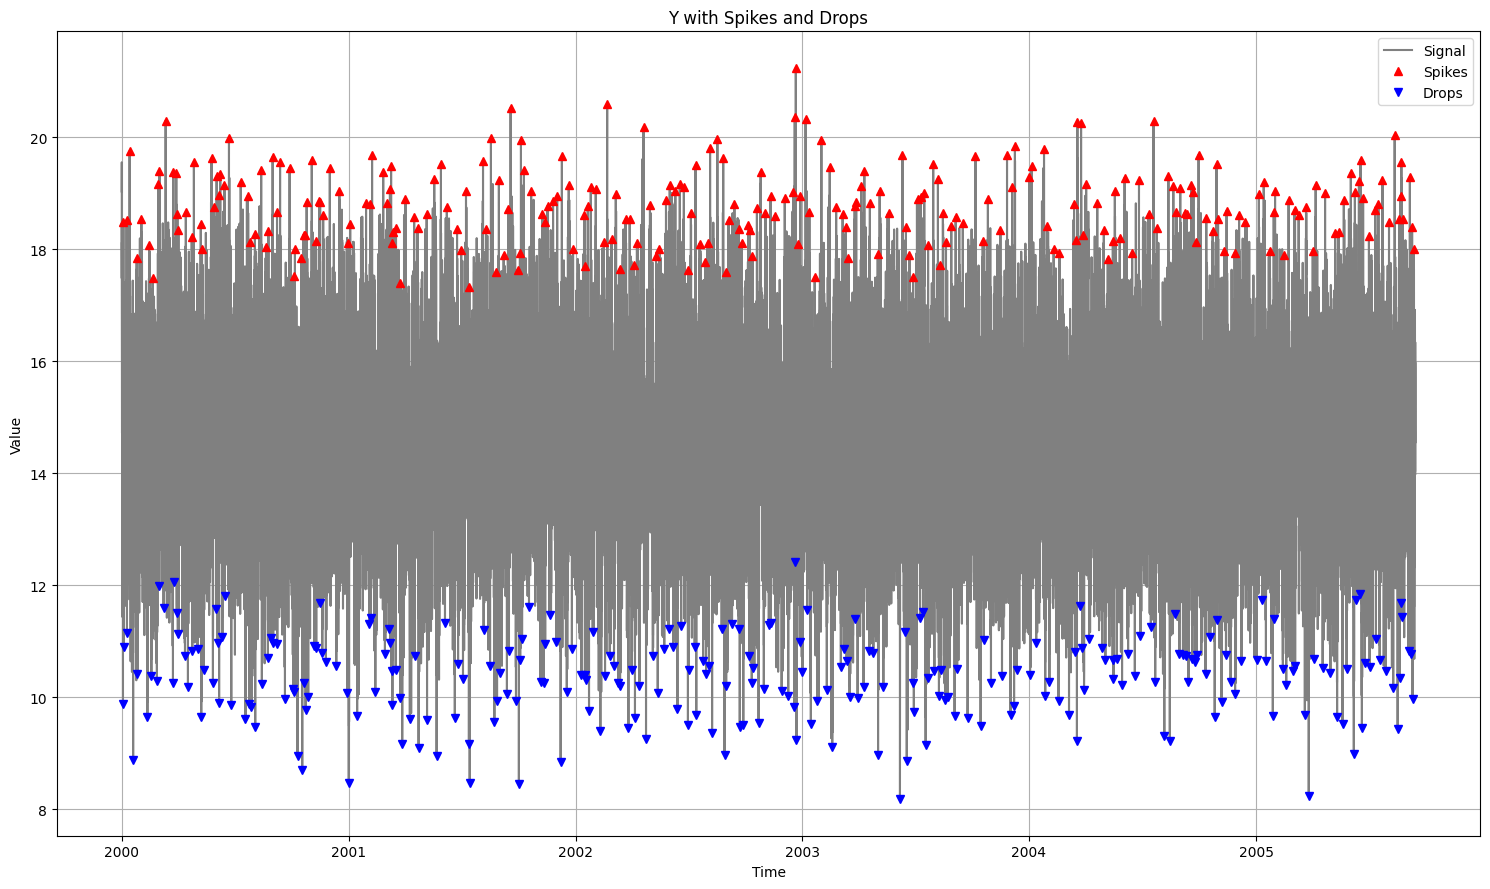

In [22]:
plot_spikes_and_drops(df.index,
                      df['y'], 
                      title="Y with Spikes and Drops",
                      prominence=6.5, robust=True)

### Weekly Patterns Analysis (based on hourly analysis)

In [26]:
y_hour_endog = df['y'].resample('H').mean()

C:\Users\HP\AppData\Local\Temp\ipykernel_11964\497068696.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  y_hour_endog = df['y'].resample('H').mean()


In [29]:
df.columns

Index(['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'y'], dtype='object')

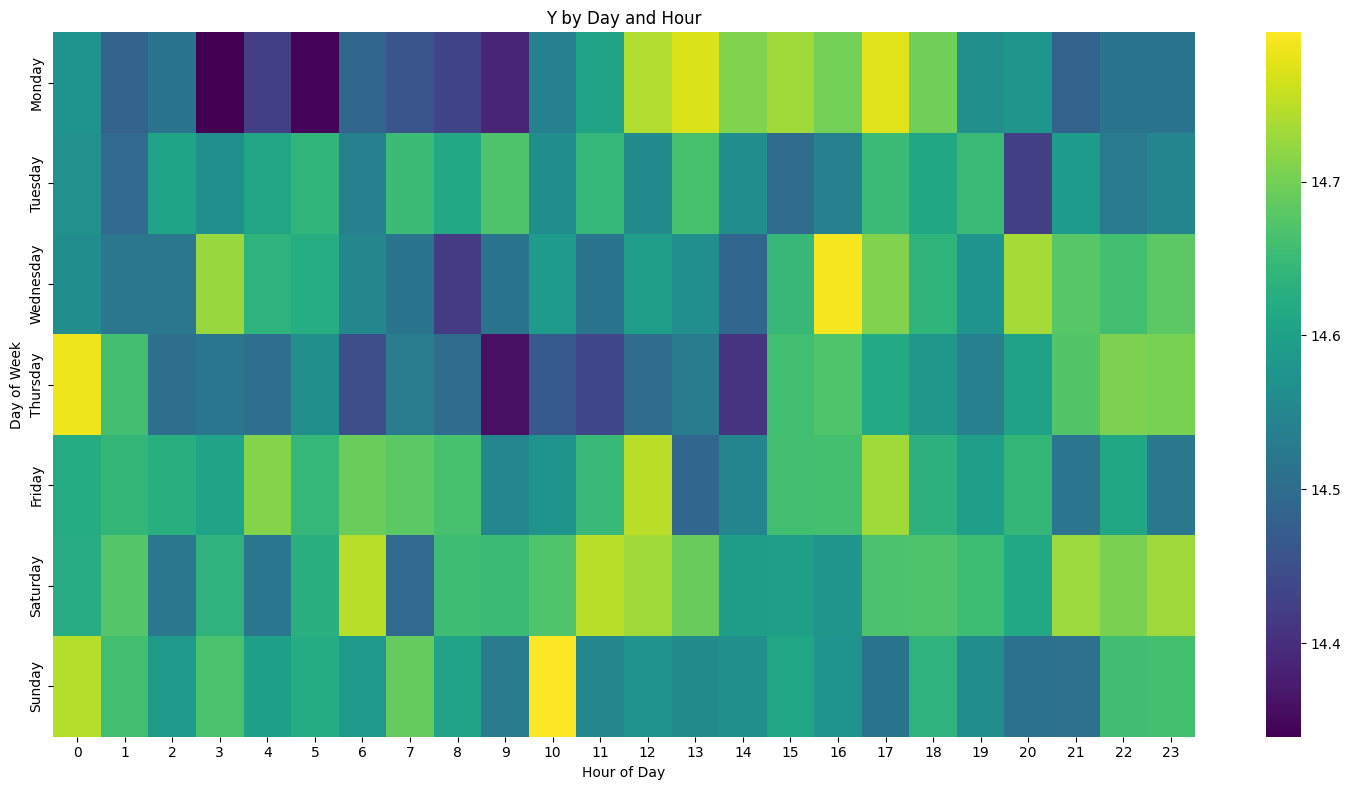

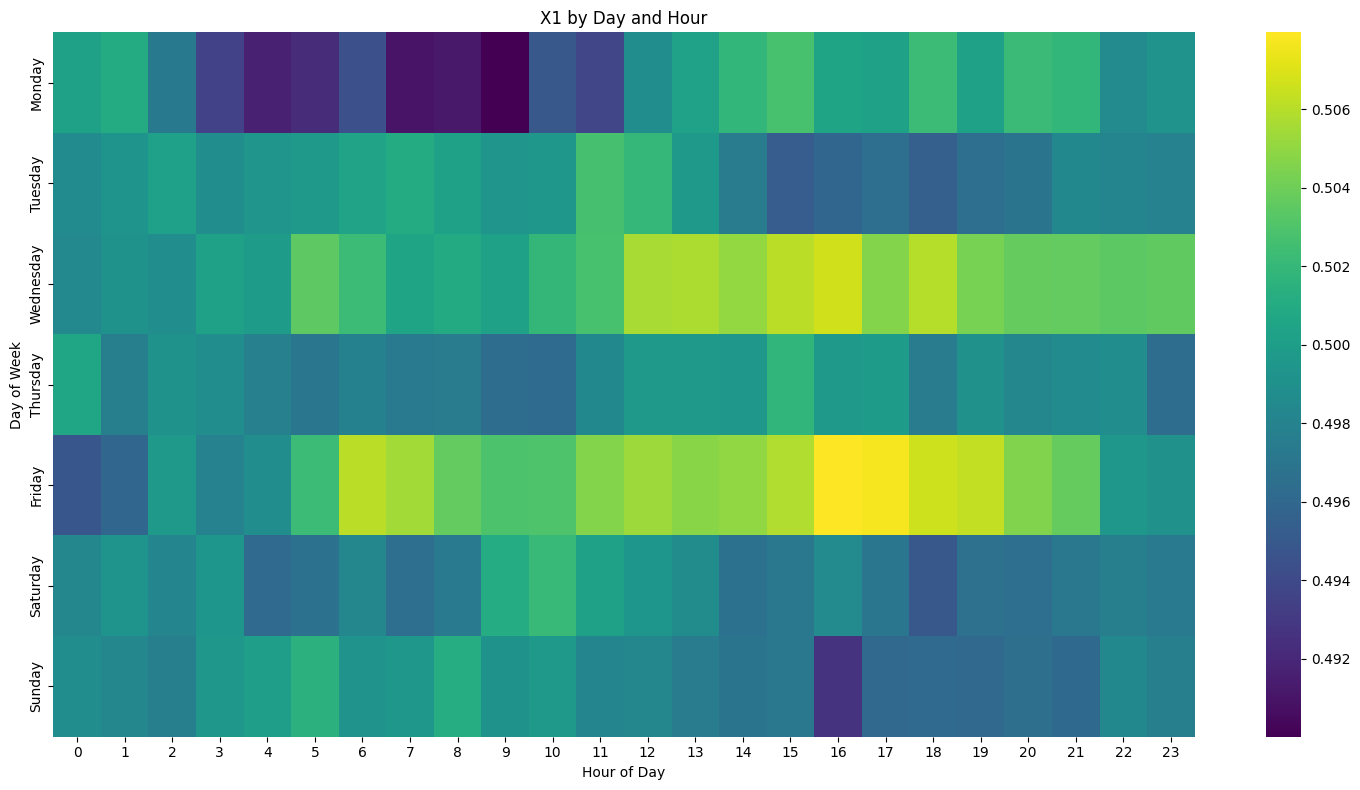

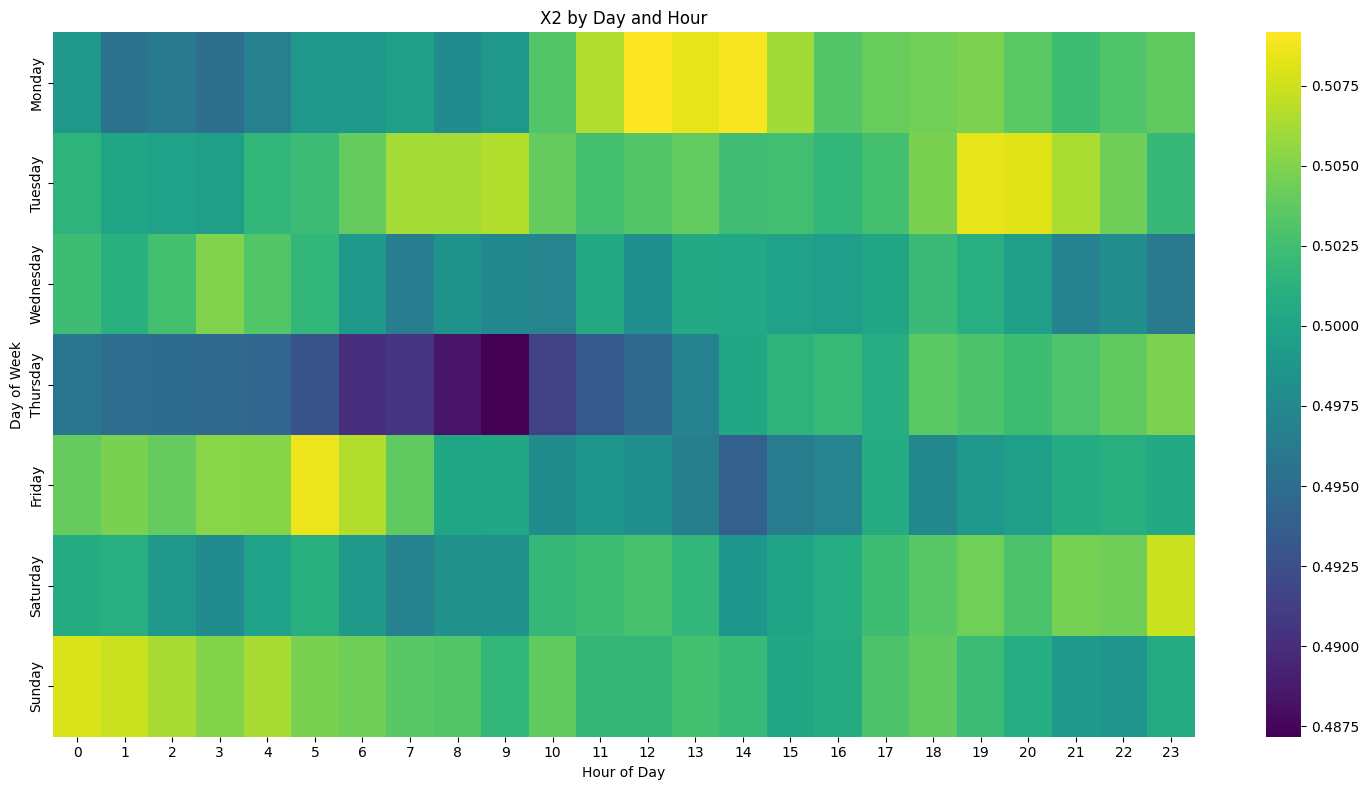

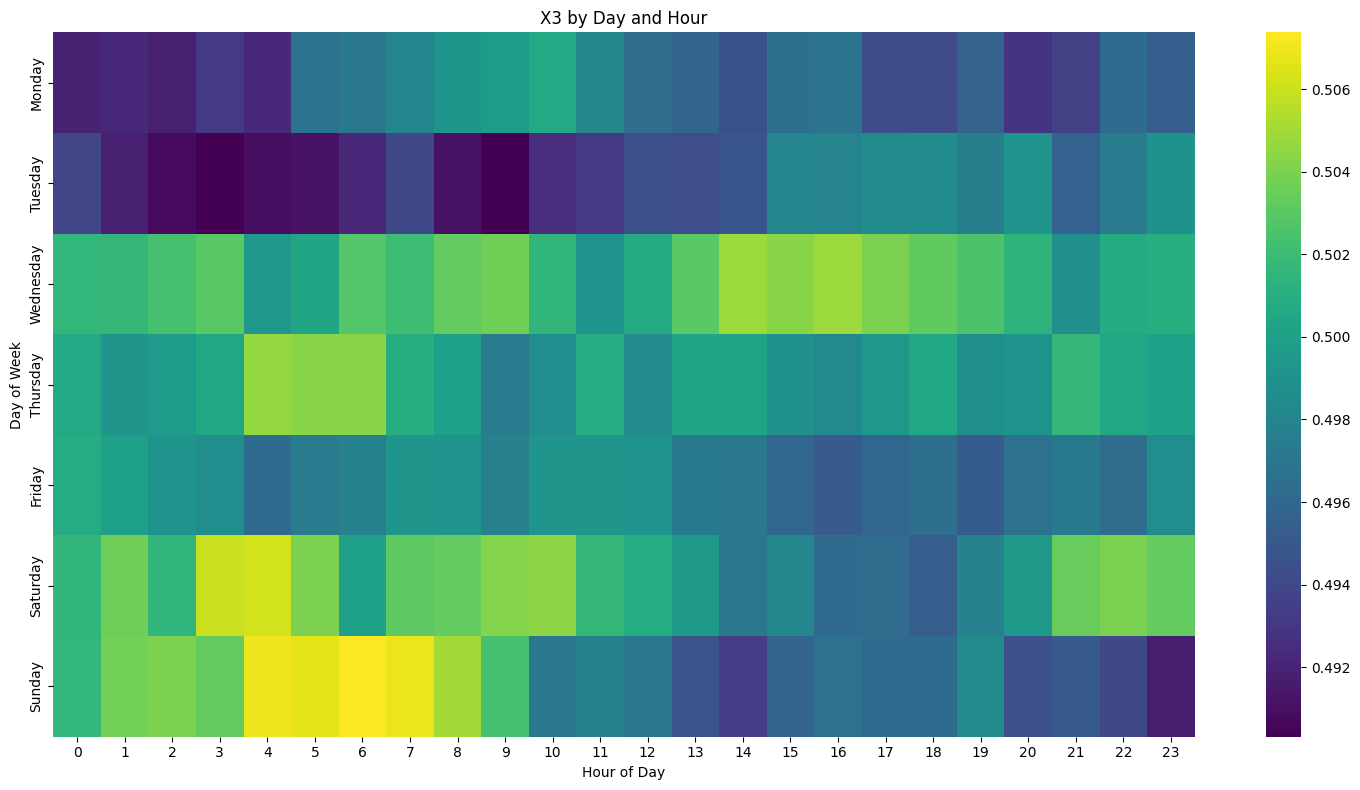

In [37]:
# Extract day of week and hour
df['day_of_week'] = df.index.day_name()
df['hour'] = df.index.hour

# Group by day of week and hour
daily_patterns = df.groupby(['day_of_week', 'hour']).agg({
    'y': 'mean',
    'x1': 'mean',
    'x2': 'mean',
    'x3': 'mean',
}).reset_index()

# Order days correctly
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_patterns['day_of_week'] = pd.Categorical(daily_patterns['day_of_week'], categories=day_order, ordered=True)
daily_patterns = daily_patterns.sort_values(['day_of_week', 'hour'])

# Plot heatmap for each column
for column in ['y', 'x1', 'x2', 'x3']:
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values=column)
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title(f'{column.replace("_", " ").title()} by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

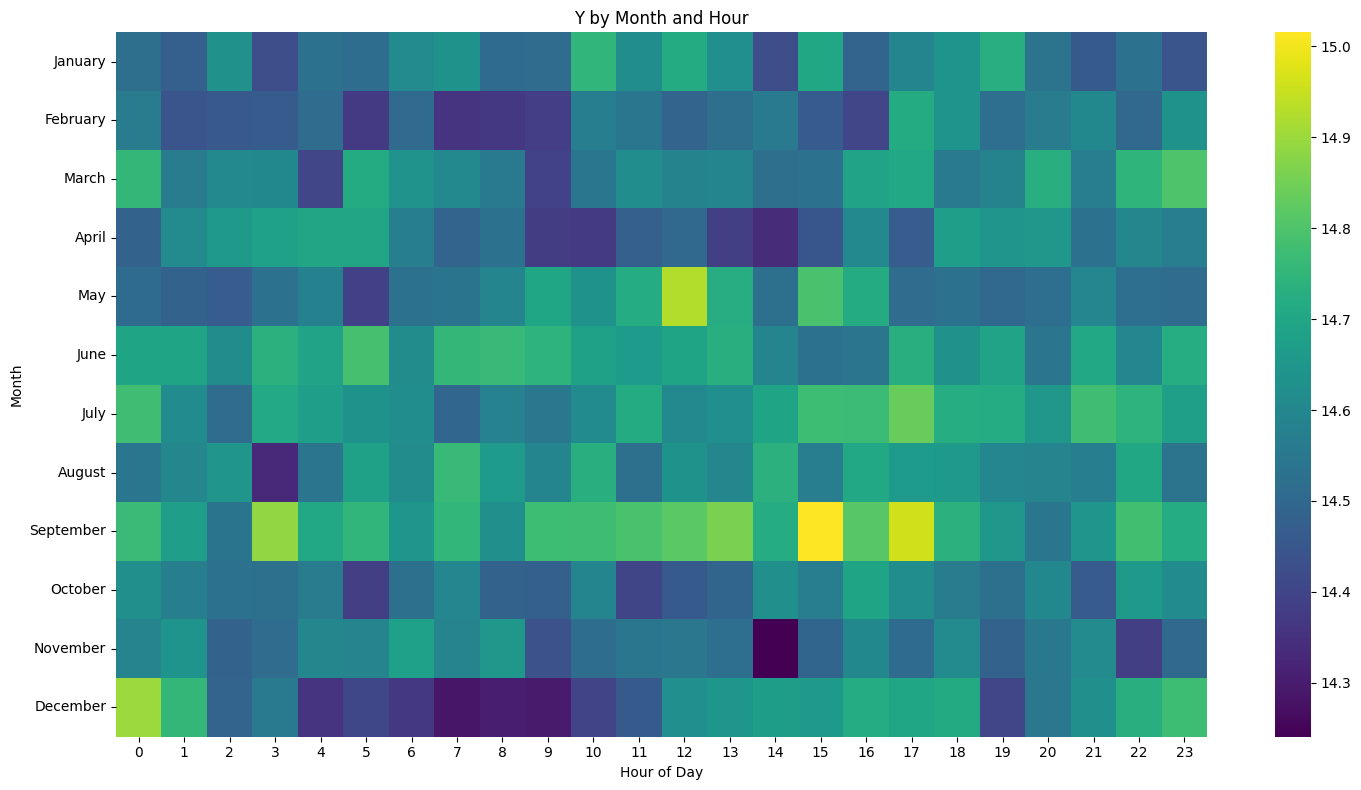

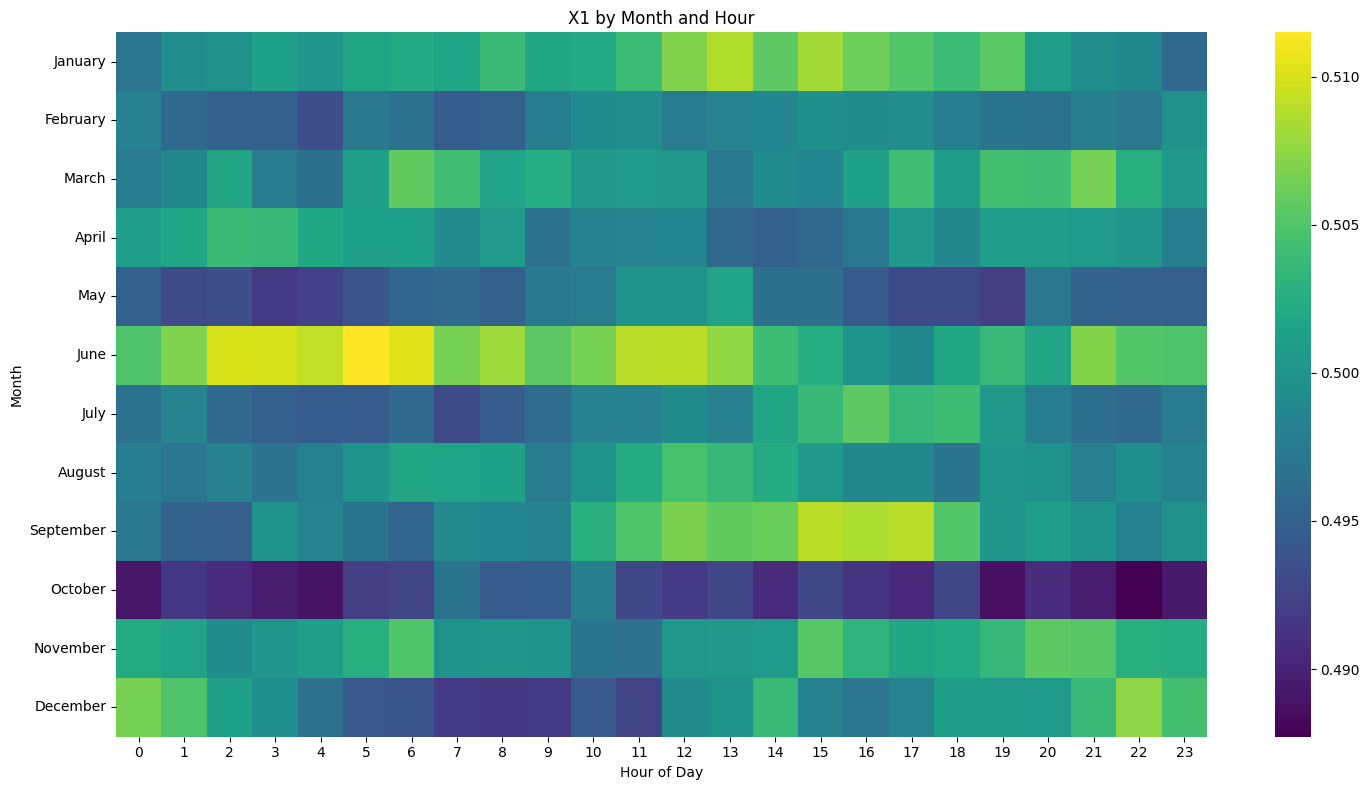

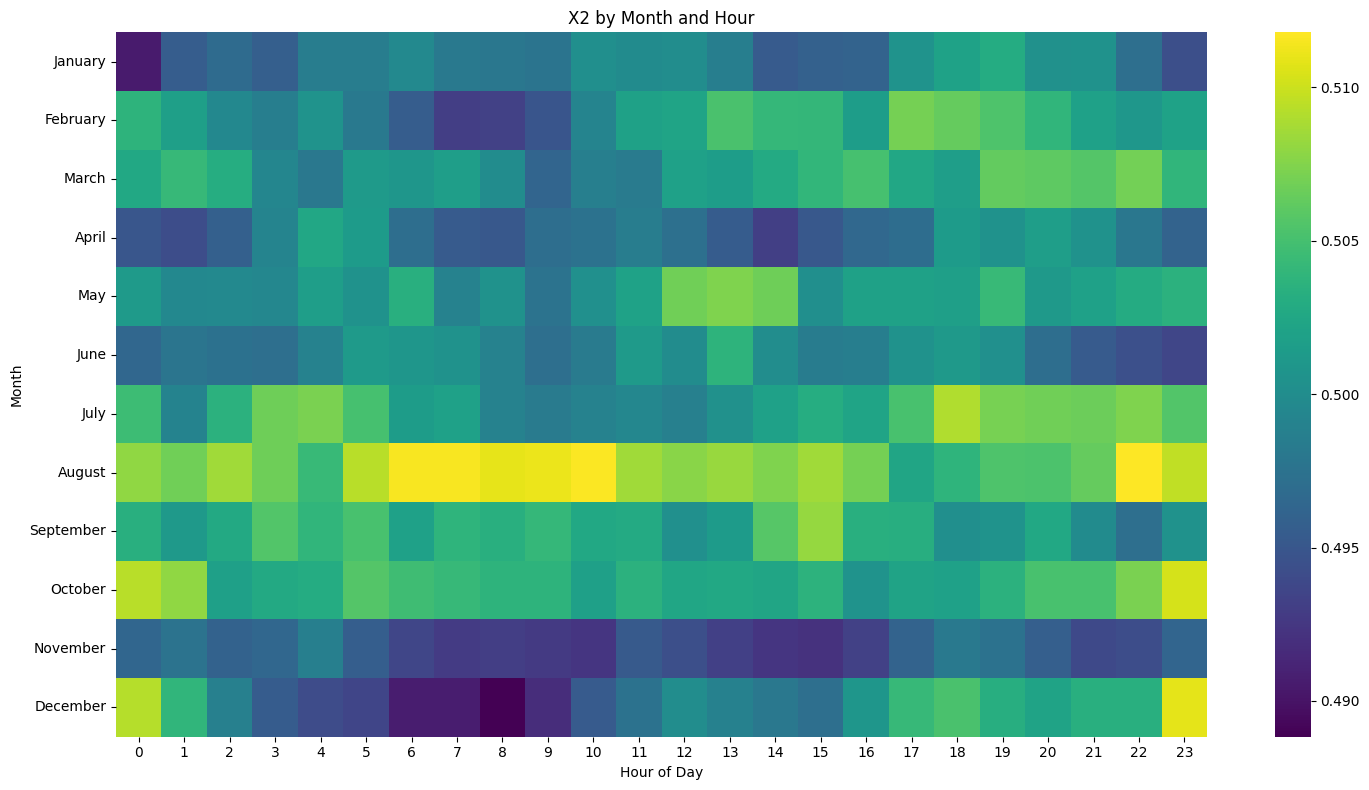

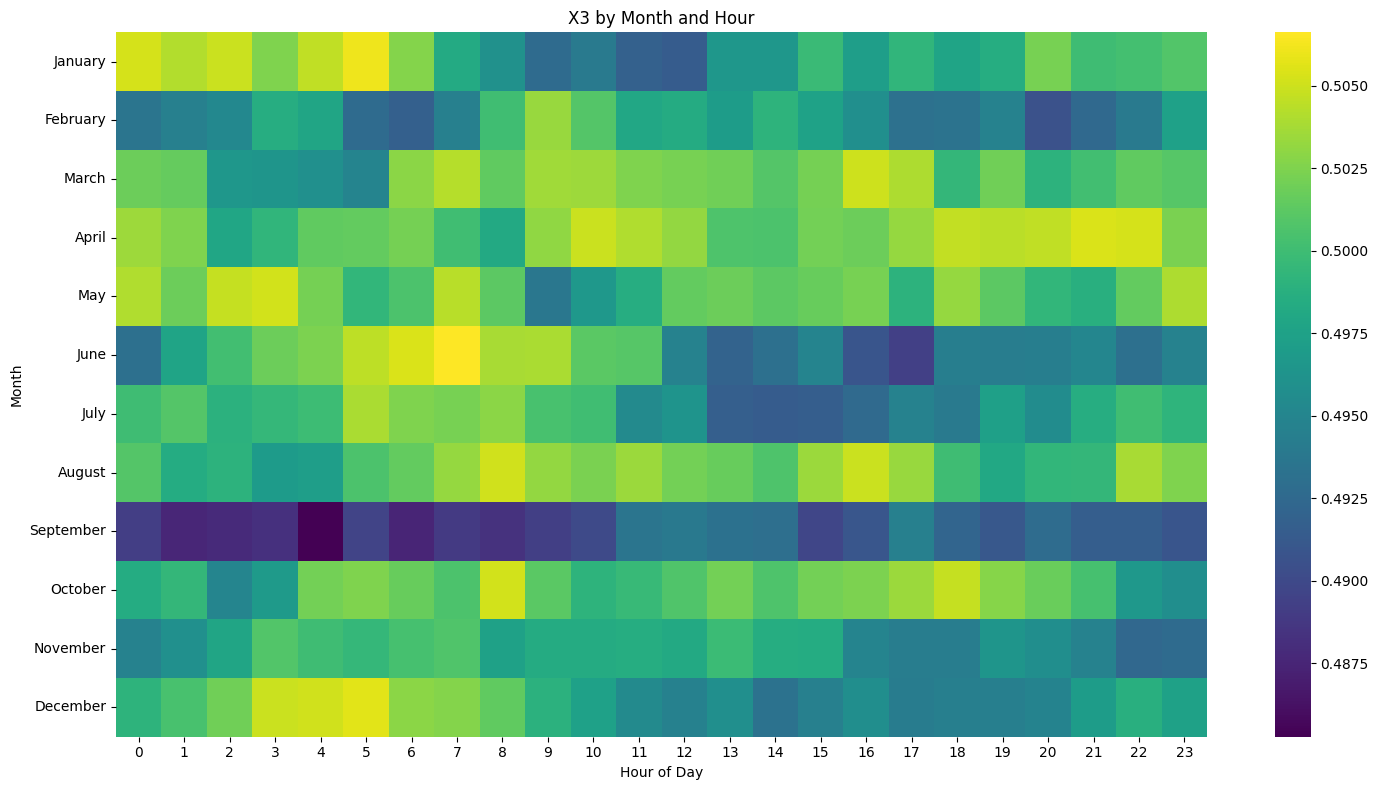

In [38]:
# Extract month and hour
df['month'] = df.index.month_name()
df['hour'] = df.index.hour

# Group by month and hour
monthly_patterns = df.groupby(['month', 'hour']).agg({
    'y': 'mean',
    'x1': 'mean',
    'x2': 'mean',
    'x3': 'mean',
}).reset_index()

# Order months correctly
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
monthly_patterns['month'] = pd.Categorical(monthly_patterns['month'], categories=month_order, ordered=True)
monthly_patterns = monthly_patterns.sort_values(['month', 'hour'])

# Plot heatmap for each column
for column in ['y', 'x1', 'x2', 'x3']:
    pivot_table = monthly_patterns.pivot(index='month', columns='hour', values=column)
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title(f'{column.replace("_", " ").title()} by Month and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Month')
    plt.tight_layout()
    plt.show()


### Autocorrelation Analysis

<Figure size 1500x600 with 0 Axes>

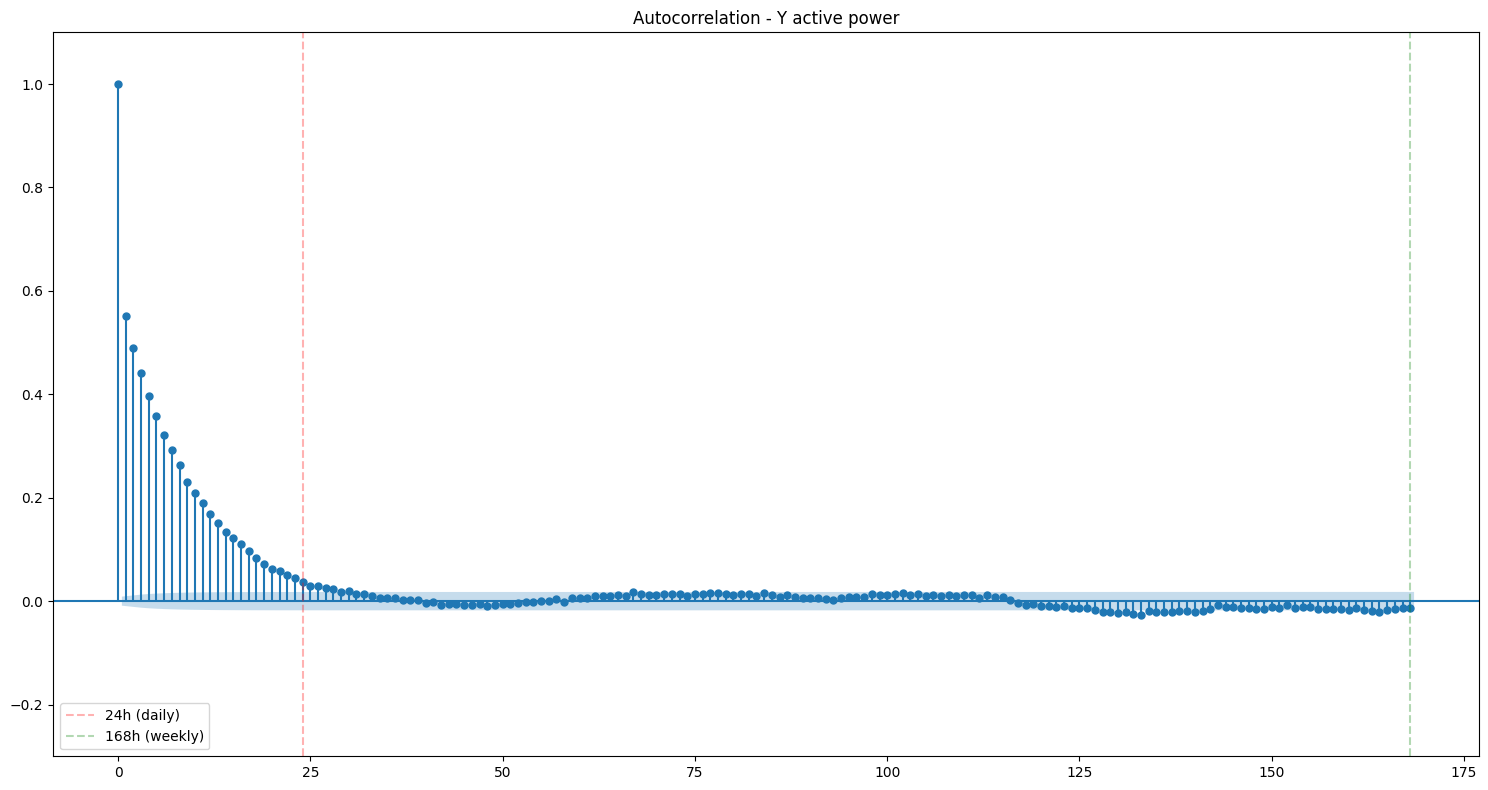

<Figure size 1500x600 with 0 Axes>

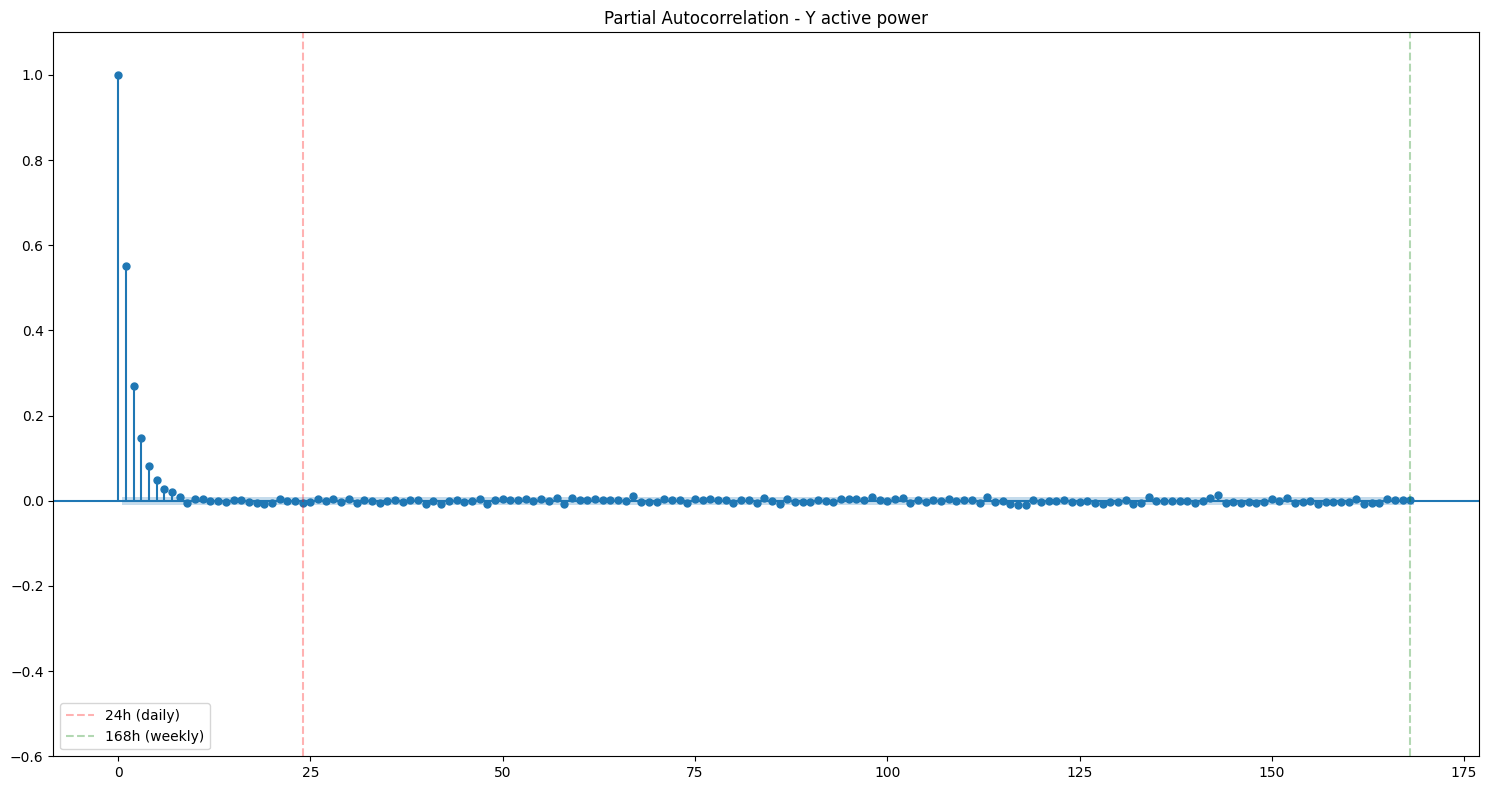

In [39]:
def plot_acf_pacf(series, lags, phase_label):
    fill_value = series.median() if not pd.isna(series.median()) else -100
    filled_series = series.fillna(fill_value)
    
    plt.figure(figsize=(15, 6))
    plot_acf(filled_series, lags=lags, title=f'Autocorrelation - {phase_label} active power')
    plt.ylim(-0.3, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(15, 6))
    plot_pacf(filled_series, lags=lags, title=f'Partial Autocorrelation - {phase_label} active power')
    plt.ylim(-0.6, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_acf_pacf(y_hour_endog, lags=24*7, phase_label='Y')